In [35]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy import stats
import cv2

In [29]:
# 1. Função de Convolução 2D Manual (para filtros lineares)
def convolucao_2d(imagem: np.ndarray, kernel: np.ndarray) -> np.ndarray:

    img_h, img_w = imagem.shape
    k_h, k_w = kernel.shape

    pad_y = k_h // 2
    pad_x = k_w // 2

    # Preenchimento de borda com reflexão para evitar corte dimensional
    img_padded = np.pad(imagem, ((pad_y, pad_y), (pad_x, pad_x)), mode='reflect')

    # Rotação de 180 graus no kernel (definição matemática da convolução)
    kernel_rot = np.flip(np.flip(kernel, axis=0), axis=1)

    saida = np.zeros((img_h, img_w), dtype=np.float32)

    for y in range(img_h):
        for x in range(img_w):
            # Recorta a região de vizinhança
            regiao = img_padded[y:y + k_h, x:x + k_w]
            # Multiplicação elemento a elemento e somatório
            saida[y, x] = np.sum(regiao * kernel_rot)

    return np.clip(saida, 0, 255).astype(np.uint8)

In [30]:
# 2. Filtro da Média (Linear)
def filtro_media(imagem: np.ndarray, tamanho: int = 3) -> np.ndarray:
    """Filtro espacial linear baseado na média aritmética local."""
    # Gera a matriz de 1s com o tamanho desejado
    kernel = np.ones((tamanho, tamanho), dtype=np.float32)

    # SUA LINHA INTEGRADA AQUI:
    kernel = kernel / np.sum(kernel)

    # Chama a convolução manual (sem cv2.filter2D)
    return convolucao_2d(imagem, kernel)

In [31]:
# 3. Filtro da Mediana (Não-linear)
def filtro_mediana(imagem: np.ndarray, tamanho: int = 3) -> np.ndarray:
    """Filtro espacial não-linear de ordenação estatística (mediana)."""
    img_h, img_w = imagem.shape
    pad = tamanho // 2
    img_padded = np.pad(imagem, pad, mode='reflect')

    saida = np.zeros((img_h, img_w), dtype=np.uint8)

    for y in range(img_h):
        for x in range(img_w):
            janela = img_padded[y:y + tamanho, x:x + tamanho]
            saida[y, x] = np.median(janela)

    return saida


In [32]:
# 4. Filtro da Moda (Não-linear)
def filtro_moda(imagem: np.ndarray, tamanho: int = 3) -> np.ndarray:
    """Filtro espacial não-linear baseado no valor mais frequente da vizinhança."""
    img_h, img_w = imagem.shape
    pad = tamanho // 2
    img_padded = np.pad(imagem, pad, mode='reflect')

    saida = np.zeros((img_h, img_w), dtype=np.uint8)

    for y in range(img_h):
        for x in range(img_w):
            janela = img_padded[y:y + tamanho, x:x + tamanho]
            # Modo estatístico da vizinhança
            moda_resultado = stats.mode(janela, axis=None, keepdims=False)
            saida[y, x] = moda_resultado.mode

    return saida

In [33]:
# 5. Filtro de Máxima / Dilatação em tons de cinza (Não-linear)
def filtro_maxima(imagem: np.ndarray, tamanho: int = 3) -> np.ndarray:
    """Filtro espacial não-linear que atribui o maior pixel da vizinhança."""
    img_h, img_w = imagem.shape
    pad = tamanho // 2
    img_padded = np.pad(imagem, pad, mode='reflect')

    saida = np.zeros((img_h, img_w), dtype=np.uint8)

    for y in range(img_h):
        for x in range(img_w):
            janela = img_padded[y:y + tamanho, x:x + tamanho]
            saida[y, x] = np.max(janela)

    return saida

In [41]:
def plot_comparativo_todos(img_original, resultados_filtros):

    n_filtros = len(resultados_filtros)
    fig, axes = plt.subplots(n_filtros, 2, figsize=(10, 4 * n_filtros))

    for i, (nome_filtro, img_filtrada) in enumerate(resultados_filtros):
        # Imagem Original
        axes[i, 0].imshow(img_original, cmap='gray')
        axes[i, 0].set_title("Imagem Original")
        axes[i, 0].axis('off')

        # Imagem Filtrada
        axes[i, 1].imshow(img_filtrada, cmap='gray')
        axes[i, 1].set_title(nome_filtro)
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

#Execução

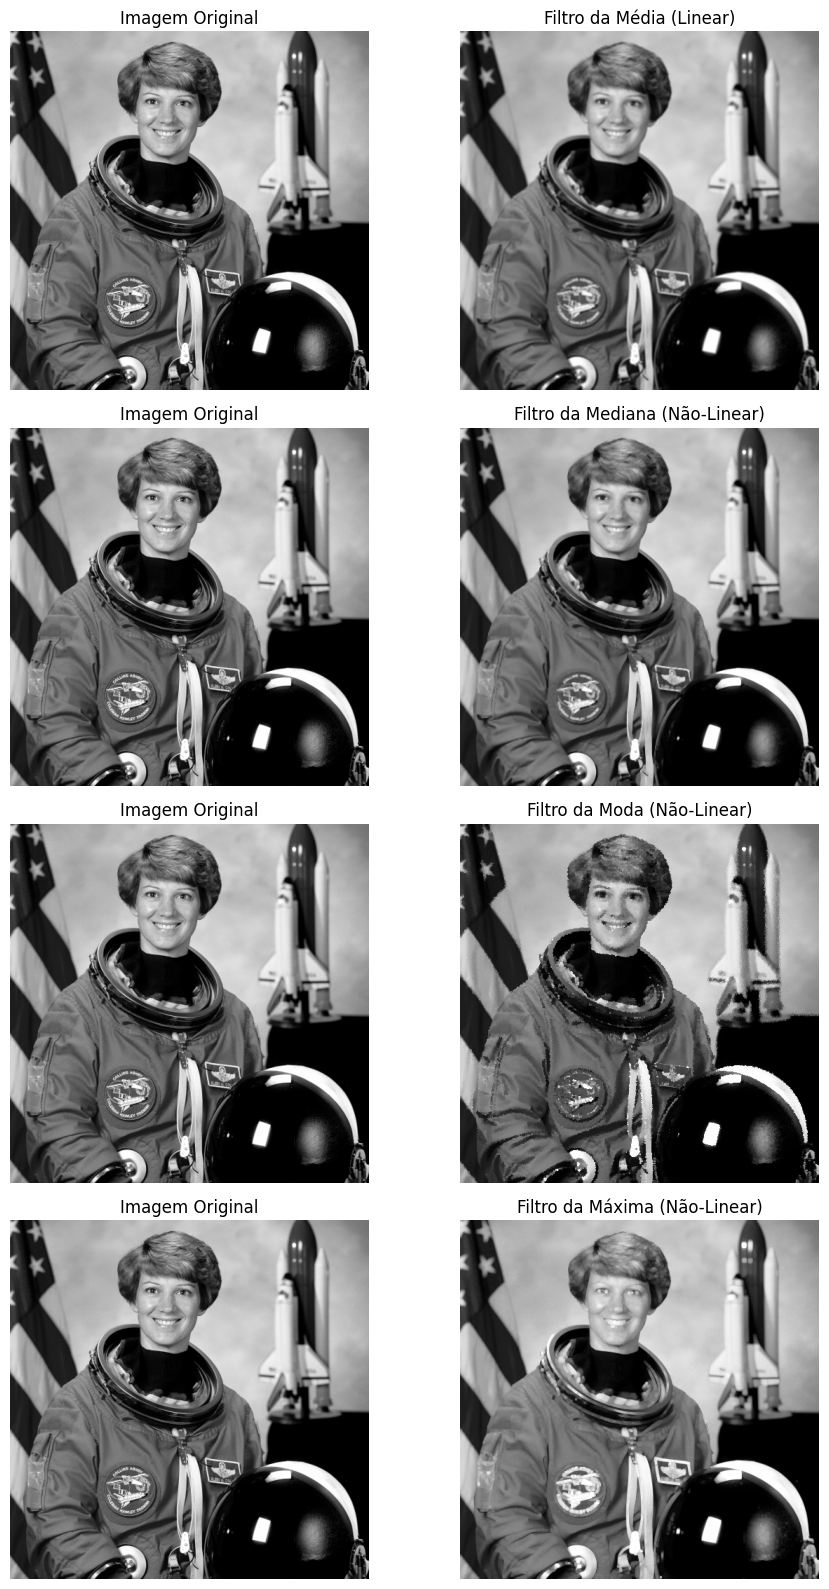

In [42]:
# Carregando imagem em escala de cinza de skimage
img_original = data.astronaut()
img_cinza = cv2.cvtColor(img_original,cv2.COLOR_BGR2GRAY)

# Subamostragem 2x apenas para reduzir o tempo de execução no loop manual

# Aplicação dos filtros com máscara 3x3
res_media = filtro_media(img_cinza, tamanho=3)
res_mediana = filtro_mediana(img_cinza, tamanho=3)
res_moda = filtro_moda(img_cinza, tamanho=3)
res_maxima = filtro_maxima(img_cinza, tamanho=3)

# Exibição com Subplots Comparativos
filtros = [
    ("Filtro da Média (Linear)", res_media),
    ("Filtro da Mediana (Não-Linear)", res_mediana),
    ("Filtro da Moda (Não-Linear)", res_moda),
    ("Filtro da Máxima (Não-Linear)", res_maxima)
]

plot_comparativo_todos(img_cinza, filtros)